# API 

In [2]:
import time
import requests
import pandas as pd
import numpy as np


BASE_URL = "https://openlibrary.org/search.json"
HEADERS = {"User-Agent": "g_satybaldyyeva@kbtu.kz"}  
FIELDS = "key,title,author_name,first_publish_year,number_of_pages_median,edition_count,ratings_average,ratings_count"

GENRES = ["fantasy", "science fiction", "mystery", "romance", "thriller",
          "horror", "historical fiction", "biography", "history", "children"]
PAGES_PER_GENRE = 3     
LIMIT = 100

def fetch_genre(genre, pages=PAGES_PER_GENRE):
    rows = []
    for page in range(1, pages + 1):
        params = {
            "q": f'subject:"{genre}"', 
            "fields": FIELDS,
            "limit": LIMIT, 
            "page": page, 
            "sort": "editions"
        }
        try:
            r = requests.get(BASE_URL, params=params, headers=HEADERS, timeout=30)
            r.raise_for_status()
            docs = r.json().get("docs", [])
        except requests.RequestException as e:
            print(f"Request failed for {genre}, page {page}: {e}")
            break
            
        if not docs:
            break
            
        for d in docs:
            d["genre"] = genre
        rows.extend(docs)
        time.sleep(1)  
    return rows


all_rows = []
for g in GENRES:
    got = fetch_genre(g)
    print(f"{g:20s} = {len(got)} records")
    all_rows.extend(got)


raw_df = pd.DataFrame(all_rows)
raw_df.to_csv("books_api_raw.csv", index=False)


fantasy              = 300 records
science fiction      = 300 records
mystery              = 300 records
romance              = 300 records
thriller             = 300 records
horror               = 300 records
historical fiction   = 300 records
biography            = 300 records
history              = 300 records
children             = 300 records


In [3]:
print("Raw shape:", raw_df.shape)
print("Missing value:")
print(raw_df.isna().sum())
print("Duplicate book keys:", raw_df.duplicated(subset="key").sum())

Raw shape: (3000, 9)
Missing value:
author_name                0
edition_count              0
first_publish_year         0
key                        0
number_of_pages_median     9
title                      0
ratings_average           70
ratings_count             70
genre                      0
dtype: int64
Duplicate book keys: 992


In [4]:
df = raw_df.copy()

df = df.rename(columns={
    "key": "work_id",
    "author_name": "authors",
    "first_publish_year": "publication_year",
    "number_of_pages_median": "page_count",
    "edition_count": "edition_count",
    "ratings_average": "rating_avg",
    "ratings_count": "rating_count",
})

df["author"] = df["authors"].apply(
    lambda x: x[0] if isinstance(x, list) and len(x) > 0 else np.nan
)
df = df.drop(columns="authors")

df["title"] = df["title"].astype("string").str.strip()
df["genre"] = df["genre"].astype("category")
for col in ["publication_year", "page_count", "edition_count", "rating_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["rating_avg"] = pd.to_numeric(df["rating_avg"], errors="coerce")

before = len(df)
df = df.drop_duplicates(subset=["work_id", "genre"])
print(f"\nDuplicates removed: {before - len(df)}")

before = len(df)
df = df.dropna(subset=["title", "publication_year", "page_count"])
print(f"Rows dropped for missing title/year/pages: {before - len(df)}")

before = len(df)
df = df[df["publication_year"].between(1000, 2026) & df["page_count"].between(20, 3000)]
print(f"Rows dropped as outliers/invalid: {before - len(df)}")

df["publication_year"] = df["publication_year"].astype(int)
df["page_count"] = df["page_count"].astype(int)

df["decade"] = (df["publication_year"] // 10) * 10

df = df.reset_index(drop=True)

df.to_csv("books_api_clean.csv", index=False)
print(f"\Done with csv dataset")

print("Clean shape:", df.shape)
print("\nData Types:")
print(df.dtypes)
print("\nMissing values in Clean Data:", df.isna().sum())

display(df.describe())


Duplicates removed: 0
Rows dropped for missing title/year/pages: 9
Rows dropped as outliers/invalid: 12


<>:44: SyntaxWarning: invalid escape sequence '\D'
<>:44: SyntaxWarning: invalid escape sequence '\D'
C:\Users\777\AppData\Local\Temp\ipykernel_12308\1099287105.py:44: SyntaxWarning: invalid escape sequence '\D'
  print(f"\Done with csv dataset")


\Done with csv dataset
Clean shape: (2979, 10)

Data Types:
edition_count          int64
publication_year       int64
work_id                  str
page_count             int64
title                 string
rating_avg           float64
rating_count         float64
genre               category
author                   str
decade                 int64
dtype: object

Missing values in Clean Data: edition_count        0
publication_year     0
work_id              0
page_count           0
title                0
rating_avg          65
rating_count        65
genre                0
author               0
decade               0
dtype: int64


,edition_count,publication_year,page_count,rating_avg,rating_count,decade
count,2979.000000,2979.000000,2979.000000,2914.000000,2914.000000,2979.000000
mean,330.611950,1886.833165,304.291037,3.431444,39.561084,1882.742531
std,461.787397,105.395408,175.571555,1.359380,89.254800,105.177412
min,32.000000,1000.000000,26.000000,0.000000,0.000000,1000.000000
25%,91.000000,1861.000000,189.000000,3.444444,2.000000,1860.000000
50%,167.000000,1907.000000,260.000000,3.928571,8.000000,1900.000000
75%,386.000000,1951.500000,393.500000,4.161849,32.000000,1950.000000
max,6110.000000,2014.000000,1462.000000,5.000000,1057.000000,2010.000000


### average page count 

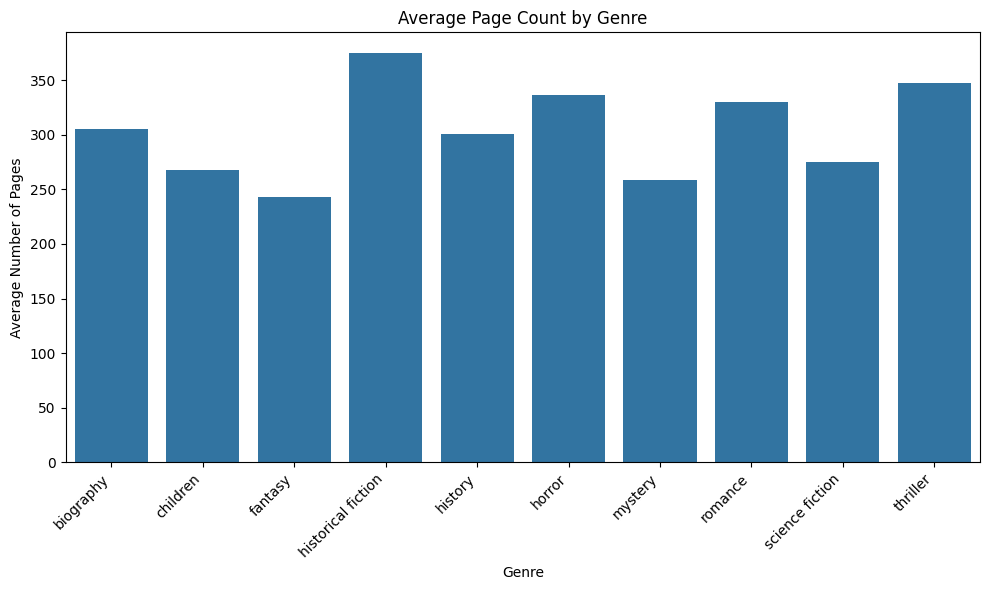

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="genre",
    y="page_count",
    errorbar=None
)

plt.title("Average Page Count by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Number of Pages")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Web scrapping 

In [6]:
import re
import requests
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from urllib.robotparser import RobotFileParser

URL = "https://en.wikipedia.org/wiki/List_of_best-selling_books"
HEADERS = {"User-Agent": "a_yessenzhanuly@kbtu.kz"}


robots = requests.get("https://en.wikipedia.org/robots.txt", headers=HEADERS, timeout=30)
rp = RobotFileParser()
rp.parse(robots.text.splitlines())
print("robots.txt status:", robots.status_code)
print("Scraping allowed for this URL:", rp.can_fetch(HEADERS["User-Agent"], URL))

robots.txt status: 200
Scraping allowed for this URL: True


In [7]:

response = requests.get(URL, headers=HEADERS, timeout=30)
print("Status code:", response.status_code)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")
tables = soup.find_all("table", class_="wikitable")
print("Number of wikitables on the page:", len(tables))

Status code: 200
Number of wikitables on the page: 13


In [8]:
def cell_text(cell):
    for sup in cell.find_all("sup"):
        sup.decompose()
    return re.sub(r"\s+", " ", cell.get_text()).strip()

rows = []
used_tables = 0

for table in tables:
    header_cells = table.find("tr").find_all("th")
    headers = [cell_text(th) for th in header_cells]

    
    if not headers or headers[0] != "Book" or "Genre" not in headers:
        continue
    used_tables += 1

    for tr in table.find_all("tr")[1:]:         
        cells = tr.find_all(["td", "th"])
        if len(cells) != 6:                     
            continue
        title, author, language, year, sales, genre = [cell_text(c) for c in cells]
        rows.append({
            "title": title,
            "authors": author,
            "language": language,
            "first_published": year,
            "sales_text": sales,
            "genre_raw": genre,
        })

print("Tables used:", used_tables)
raw_df = pd.DataFrame(rows)
raw_df.to_csv("books_scraped_raw.csv", index=False)
print("Raw shape:", raw_df.shape)
raw_df.head(10)

Tables used: 4
Raw shape: (169, 6)


,title,authors,language,first_published,sales_text,genre_raw
0,A Tale of Two Cities,Charles Dickens,English,1859,>200 million,Historical fiction
1,The Little Prince (Le Petit Prince),Antoine de Saint-Exupéry,French,1943,200 million,Fantasy
2,The Alchemist (O Alquimista),Paulo Coelho,Portuguese,1988,150 million,Fantasy
3,Harry Potter and the Philosopher's Stone,J. K. Rowling,English,1997,120 million,Fantasy
4,And Then There Were None,Agatha Christie,English,1939,100 million,Mystery
5,Dream of the Red Chamber (紅樓夢),Cao Xueqin,Chinese,1791,100 million,Family saga
6,The Hobbit,J. R. R. Tolkien,English,1937,100 million,"Fantasy, children's fiction"
7,Alice's Adventures in Wonderland,Lewis Carroll,English,1865,100 million,"Fantasy, absurdist fiction"
8,She: A History of Adventure,H. Rider Haggard,English,1887,83 million,Adventure
9,The Da Vinci Code,Dan Brown,English,2003,80 million,Mystery thriller


In [9]:
df = raw_df.copy()


df = df.replace("", np.nan)


df["title"] = df["title"].str.replace(r"\s*\(.*?\)", "", regex=True).str.strip()
df["title_clean"] = (df["title"].str.lower()
                                .str.replace(r"[^\w\s]", "", regex=True)
                                .str.replace(r"\s+", " ", regex=True)
                                .str.strip())


df["author"] = df["authors"].str.split(r",| and ", regex=True).str[0].str.strip()
df = df.drop(columns="authors")


df["publication_year"] = pd.to_numeric(df["first_published"].str.extract(r"(\d{4})")[0], errors="coerce")
df = df.drop(columns="first_published")


df["sales_millions"] = pd.to_numeric(df["sales_text"].str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")


df["wiki_genre"] = df["genre_raw"].str.split(",").str[0].str.strip().str.lower()


print("Duplicate title+author:", df.duplicated(subset=["title_clean", "author"]).sum())
df = df.drop_duplicates(subset=["title_clean", "author"])

before = len(df)
df = df.dropna(subset=["title", "publication_year", "sales_millions"])
print("Rows dropped for missing title/year/sales:", before - len(df))

df["publication_year"] = df["publication_year"].astype(int)
df["decade"] = (df["publication_year"] // 10) * 10

df = df[["title", "title_clean", "author", "language", "publication_year", "decade",
         "sales_millions", "wiki_genre", "genre_raw", "sales_text"]].reset_index(drop=True)

df.to_csv("books_scraped_clean.csv", index=False)
print("Done")
print()
print(df.dtypes)
print()
print("Missing values:")
print(df.isna().sum())
df.head(10)

Duplicate title+author: 0
Rows dropped for missing title/year/sales: 0
Done

title                   str
title_clean             str
author               object
language                str
publication_year      int64
decade                int64
sales_millions      float64
wiki_genre           object
genre_raw               str
sales_text              str
dtype: object

Missing values:
title                0
title_clean          0
author               0
language             0
publication_year     0
decade               0
sales_millions       0
wiki_genre          44
genre_raw           44
sales_text           0
dtype: int64


,title,title_clean,author,language,publication_year,decade,sales_millions,wiki_genre,genre_raw,sales_text
0,A Tale of Two Cities,a tale of two cities,Charles Dickens,English,1859,1850,200.0,historical fiction,Historical fiction,>200 million
1,The Little Prince,the little prince,Antoine de Saint-Exupéry,French,1943,1940,200.0,fantasy,Fantasy,200 million
2,The Alchemist,the alchemist,Paulo Coelho,Portuguese,1988,1980,150.0,fantasy,Fantasy,150 million
3,Harry Potter and the Philosopher's Stone,harry potter and the philosophers stone,J. K. Rowling,English,1997,1990,120.0,fantasy,Fantasy,120 million
4,And Then There Were None,and then there were none,Agatha Christie,English,1939,1930,100.0,mystery,Mystery,100 million
5,Dream of the Red Chamber,dream of the red chamber,Cao Xueqin,Chinese,1791,1790,100.0,family saga,Family saga,100 million
6,The Hobbit,the hobbit,J. R. R. Tolkien,English,1937,1930,100.0,fantasy,"Fantasy, children's fiction",100 million
7,Alice's Adventures in Wonderland,alices adventures in wonderland,Lewis Carroll,English,1865,1860,100.0,fantasy,"Fantasy, absurdist fiction",100 million
8,She: A History of Adventure,she a history of adventure,H. Rider Haggard,English,1887,1880,83.0,adventure,Adventure,83 million
9,The Da Vinci Code,the da vinci code,Dan Brown,English,2003,2000,80.0,mystery thriller,Mystery thriller,80 million


In [10]:
df[["publication_year", "sales_millions"]].describe()

,publication_year,sales_millions
count,169.000000,169.000000
mean,1961.769231,29.184024
std,65.609959,29.169193
min,1304.000000,10.000000
25%,1947.000000,12.000000
50%,1974.000000,20.000000
75%,1995.000000,35.000000
max,2018.000000,200.000000


### top 10 best selling books

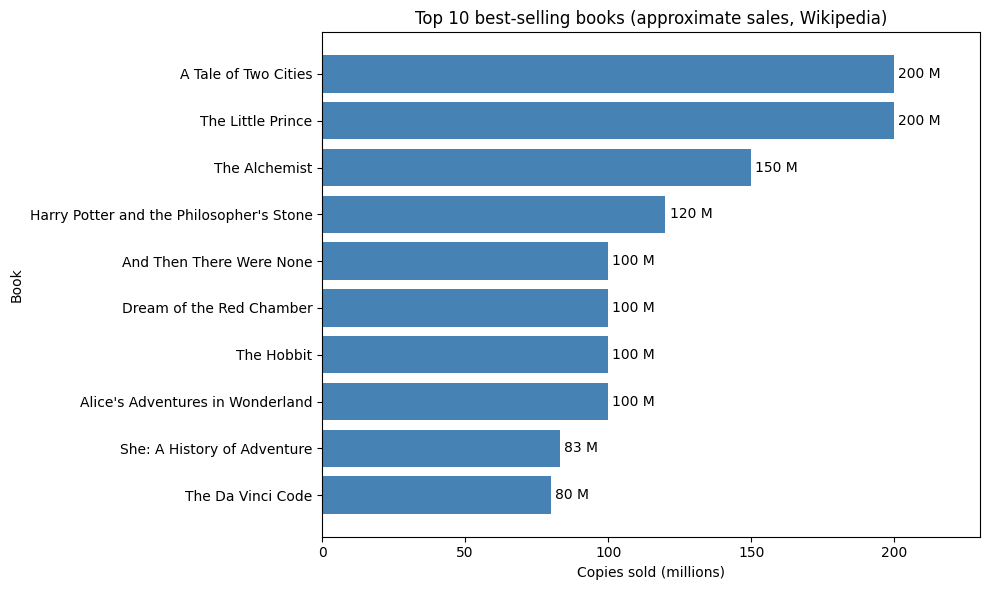

In [11]:
top10 = df.nlargest(10, "sales_millions").sort_values("sales_millions")   # sorted so the biggest bar is on top

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10["title"], top10["sales_millions"], color="steelblue")
ax.bar_label(bars, fmt="%.0f M", padding=3)

ax.set_title("Top 10 best-selling books (approximate sales, Wikipedia)")
ax.set_xlabel("Copies sold (millions)")
ax.set_ylabel("Book")
ax.set_xlim(0, top10["sales_millions"].max() * 1.15)
plt.tight_layout()
plt.savefig("top10_sales.png", dpi=150)
plt.show()

# Data cleaning and merging

In [12]:
import pandas as pd

api_df = pd.read_csv("books_api_clean.csv")
scraped_df = pd.read_csv("books_scraped_clean.csv")

print("API dataset shape:", api_df.shape)
print("Scraped dataset shape:", scraped_df.shape)

API dataset shape: (2979, 10)
Scraped dataset shape: (169, 10)


In [13]:
print("API columns:")
print(api_df.columns.tolist())

print("\nScraped columns:")
print(scraped_df.columns.tolist())

print("\nAPI first 5 rows:")
display(api_df.head())

print("\nScraped first 5 rows:")
display(scraped_df.head())

API columns:
['edition_count', 'publication_year', 'work_id', 'page_count', 'title', 'rating_avg', 'rating_count', 'genre', 'author', 'decade']

Scraped columns:
['title', 'title_clean', 'author', 'language', 'publication_year', 'decade', 'sales_millions', 'wiki_genre', 'genre_raw', 'sales_text']

API first 5 rows:


,edition_count,publication_year,work_id,page_count,title,rating_avg,rating_count,genre,author,decade
0,3548,1865,/works/OL138052W,133,Alice's Adventures in Wonderland,4.051282,234.0,fantasy,Lewis Carroll,1860
1,3196,1843,/works/OL32466W,114,A Christmas Carol,3.958678,121.0,fantasy,Charles Dickens,1840
2,3013,1890,/works/OL8193416W,246,The Picture of Dorian Gray,4.165413,133.0,fantasy,Oscar Wilde,1890
3,2420,1686,/works/OL45089W,274,Robinson Crusoe,4.000000,29.0,fantasy,Daniel Defoe,1680
4,2049,1899,/works/OL18417W,159,The Wonderful Wizard of Oz,3.953488,129.0,fantasy,L. Frank Baum,1890



Scraped first 5 rows:


,title,title_clean,author,language,publication_year,decade,sales_millions,wiki_genre,genre_raw,sales_text
0,A Tale of Two Cities,a tale of two cities,Charles Dickens,English,1859,1850,200.0,historical fiction,Historical fiction,>200 million
1,The Little Prince,the little prince,Antoine de Saint-Exupéry,French,1943,1940,200.0,fantasy,Fantasy,200 million
2,The Alchemist,the alchemist,Paulo Coelho,Portuguese,1988,1980,150.0,fantasy,Fantasy,150 million
3,Harry Potter and the Philosopher's Stone,harry potter and the philosophers stone,J. K. Rowling,English,1997,1990,120.0,fantasy,Fantasy,120 million
4,And Then There Were None,and then there were none,Agatha Christie,English,1939,1930,100.0,mystery,Mystery,100 million


In [14]:
print("API dataset")

print("\nMissing values:")
print(api_df.isnull().sum())

print("\nDuplicate rows:", api_df.duplicated().sum())

print("\nData types:")
print(api_df.dtypes)


print("\n scraped dataset")

print("\nMissing values:")
print(scraped_df.isnull().sum())

print("\nDuplicate rows:", scraped_df.duplicated().sum())

print("\nData types:")
print(scraped_df.dtypes)

API dataset

Missing values:
edition_count        0
publication_year     0
work_id              0
page_count           0
title                0
rating_avg          65
rating_count        65
genre                0
author               0
decade               0
dtype: int64

Duplicate rows: 0

Data types:
edition_count         int64
publication_year      int64
work_id                 str
page_count            int64
title                   str
rating_avg          float64
rating_count        float64
genre                   str
author                  str
decade                int64
dtype: object

 scraped dataset

Missing values:
title                0
title_clean          0
author               0
language             0
publication_year     0
decade               0
sales_millions       0
wiki_genre          44
genre_raw           44
sales_text           0
dtype: int64

Duplicate rows: 0

Data types:
title                   str
title_clean             str
author                  str
language

In [15]:
api_clean = api_df.copy()
scraped_clean = scraped_df.copy()

print("API shape before cleaning:", api_clean.shape)
print("Scraped shape before cleaning:", scraped_clean.shape)

API shape before cleaning: (2979, 10)
Scraped shape before cleaning: (169, 10)


In [16]:
scraped_clean["wiki_genre"] = scraped_clean["wiki_genre"].fillna("unknown")
scraped_clean["genre_raw"] = scraped_clean["genre_raw"].fillna("unknown")

print(scraped_clean[["wiki_genre", "genre_raw"]].isnull().sum())

wiki_genre    0
genre_raw     0
dtype: int64


In [23]:
api_clean["title_clean"] = (
    api_clean["title"]
    .str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.strip()
)

print(api_clean[["title", "title_clean"]].head(10))

                              title                      title_clean
0  Alice's Adventures in Wonderland  alices adventures in wonderland
1                 A Christmas Carol                a christmas carol
2        The Picture of Dorian Gray       the picture of dorian gray
3                   Robinson Crusoe                  robinson crusoe
4        The Wonderful Wizard of Oz       the wonderful wizard of oz
5                   Treasure Island                  treasure island
6                           Dracula                          dracula
7                Gulliver's Travels                gullivers travels
8              The Call of the Wild             the call of the wild
9                 The Secret Garden                the secret garden


In [24]:
matches = api_clean[
    api_clean["title_clean"].isin(scraped_clean["title_clean"])
]

print("Matching books:", len(matches))

display(
    matches[
        ["title", "author", "publication_year"]
    ].head(20)
)

Matching books: 104


,title,author,publication_year
0,Alice's Adventures in Wonderland,Lewis Carroll,1865
13,The Wind in the Willows,Kenneth Grahame,1908
14,Anne of Green Gables,Lucy Maud Montgomery,1908
61,The Hobbit,J.R.R. Tolkien,1937
86,Harry Potter and the Philosopher's Stone,J. K. Rowling,1997
111,Harry Potter and the Chamber of Secrets,J. K. Rowling,1998
139,Charlie and the Chocolate Factory,Roald Dahl,1964
154,Charlotte's Web,E. B. White,1952
172,Matilda,Roald Dahl,1988
189,James and the Giant Peach,Roald Dahl,1961


In [21]:
print("Duplicate titles in API:",
      api_clean.duplicated(subset=["title_clean"]).sum())

print("Duplicate titles in scraped data:",
      scraped_clean.duplicated(subset=["title_clean"]).sum())

Duplicate titles in API: 1030
Duplicate titles in scraped data: 0


In [26]:
api_clean = api_clean.drop_duplicates(
    subset=["title_clean"]
).copy()

scraped_clean = scraped_clean.drop_duplicates(
    subset=["title_clean"]
).copy()

print("API shape:", api_clean.shape)
print("Scraped shape:", scraped_clean.shape)

API shape: (1949, 11)
Scraped shape: (169, 10)


In [27]:
merged_df = pd.merge(
    api_clean,
    scraped_clean,
    on="title_clean",
    how="inner",
    suffixes=("_api", "_scraped")
)

print("Merged dataset shape:", merged_df.shape)

display(merged_df.head())

Merged dataset shape: (55, 20)


,edition_count,publication_year_api,work_id,page_count,title_api,rating_avg,rating_count,genre,author_api,decade_api,title_clean,title_scraped,author_scraped,language,publication_year_scraped,decade_scraped,sales_millions,wiki_genre,genre_raw,sales_text
0,3548,1865,/works/OL138052W,133,Alice's Adventures in Wonderland,4.051282,234.0,fantasy,Lewis Carroll,1860,alices adventures in wonderland,Alice's Adventures in Wonderland,Lewis Carroll,English,1865,1860,100.0,fantasy,"Fantasy, absurdist fiction",100 million
1,1346,1908,/works/OL28570037W,192,The Wind in the Willows,4.051724,58.0,fantasy,Kenneth Grahame,1900,the wind in the willows,The Wind in the Willows,Kenneth Grahame,English,1908,1900,25.0,children's literature,Children's literature,25 million
2,1299,1908,/works/OL77746W,309,Anne of Green Gables,4.301887,106.0,fantasy,Lucy Maud Montgomery,1900,anne of green gables,Anne of Green Gables,Lucy Maud Montgomery,English,1908,1900,50.0,children's novel,Children's novel,50 million
3,482,1937,/works/OL27482W,310,The Hobbit,4.297029,505.0,fantasy,J.R.R. Tolkien,1930,the hobbit,The Hobbit,J. R. R. Tolkien,English,1937,1930,100.0,fantasy,"Fantasy, children's fiction",100 million
4,400,1997,/works/OL82563W,302,Harry Potter and the Philosopher's Stone,4.218543,1057.0,fantasy,J. K. Rowling,1990,harry potter and the philosophers stone,Harry Potter and the Philosopher's Stone,J. K. Rowling,English,1997,1990,120.0,fantasy,Fantasy,120 million


In [29]:
merged_df["year_match"] = (
    merged_df["publication_year_api"] == merged_df["publication_year_scraped"]
)

print("Matching years:", merged_df["year_match"].sum())
print("Different years:", (~merged_df["year_match"]).sum())

display(
    merged_df.loc[
        ~merged_df["year_match"],
        [
            "title_api",
            "publication_year_api",
            "publication_year_scraped",
            "author_api",
            "author_scraped"
        ]
    ]
)

Matching years: 43
Different years: 12


,title_api,publication_year_api,publication_year_scraped,author_api,author_scraped
25,The Great Gatsby,1920,1925,F. Scott Fitzgerald,F. Scott Fitzgerald
27,Lolita,1777,1955,Vladimir Nabokov,Vladimir Nabokov
29,Paul et Virginie,1789,1788,Bernardin de Saint-Pierre,Jacques-Henri Bernardin de Saint-Pierre
30,Fifty Shades of Grey,2000,2011,E. L. James,E. L. James
37,Jaws,1973,1974,Peter Benchley,Peter Benchley
38,Adventures of Huckleberry Finn,1876,1885,Mark Twain,Mark Twain
39,A Tale of Two Cities,1800,1859,Charles Dickens,Charles Dickens
40,War and Peace,1845,1869,Лев Толстой,Leo Tolstoy
42,Heidi,1885,1880,"Spyri, Johanna",Johanna Spyri
45,The Book Thief,1998,2005,Markus Zusak,Markus Zusak


In [31]:
merged_df["year"] = merged_df["publication_year_scraped"]

print(
    merged_df[
        ["title_api", "publication_year_api", "publication_year_scraped", "year"]
    ].head(10)
)

                                  title_api  publication_year_api  \
0          Alice's Adventures in Wonderland                  1865   
1                   The Wind in the Willows                  1908   
2                      Anne of Green Gables                  1908   
3                                The Hobbit                  1937   
4  Harry Potter and the Philosopher's Stone                  1997   
5   Harry Potter and the Chamber of Secrets                  1998   
6         Charlie and the Chocolate Factory                  1964   
7                           Charlotte's Web                  1952   
8                                   Matilda                  1988   
9                 James and the Giant Peach                  1961   

   publication_year_scraped  year  
0                      1865  1865  
1                      1908  1908  
2                      1908  1908  
3                      1937  1937  
4                      1997  1997  
5                      1

In [32]:
print("Missing values in merged dataset:")
print(merged_df.isnull().sum())

print("\nDuplicate titles:")
print(merged_df.duplicated(subset=["title_clean"]).sum())

print("\nFinal shape:")
print(merged_df.shape)

Missing values in merged dataset:
edition_count               0
publication_year_api        0
work_id                     0
page_count                  0
title_api                   0
rating_avg                  0
rating_count                0
genre                       0
author_api                  0
decade_api                  0
title_clean                 0
title_scraped               0
author_scraped              0
language                    0
publication_year_scraped    0
decade_scraped              0
sales_millions              0
wiki_genre                  0
genre_raw                   0
sales_text                  0
year_match                  0
year                        0
dtype: int64

Duplicate titles:
0

Final shape:
(55, 22)


In [34]:
final_df = merged_df[
    [
        "title_scraped",
        "author_scraped",
        "year",
        "language",
        "genre",
        "wiki_genre",
        "page_count",
        "edition_count",
        "rating_avg",
        "rating_count",
        "sales_millions",
        "decade_scraped"
    ]
].copy()

final_df = final_df.rename(
    columns={
        "title_scraped" : "title",
        "author_scraped" : "author",
        "decade_scraped" : "decade",
        "page_count" : "pages",
        "rating_avg" : "ratings_average",
        "rating_count" : "ratings_count",
        "genre" : "api_genre"
    }
)

display(final_df.head())

print("Final dataset shape:", final_df.shape)

,title,author,year,language,api_genre,wiki_genre,pages,edition_count,ratings_average,ratings_count,sales_millions,decade
0,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,fantasy,133,3548,4.051282,234.0,100.0,1860
1,The Wind in the Willows,Kenneth Grahame,1908,English,fantasy,children's literature,192,1346,4.051724,58.0,25.0,1900
2,Anne of Green Gables,Lucy Maud Montgomery,1908,English,fantasy,children's novel,309,1299,4.301887,106.0,50.0,1900
3,The Hobbit,J. R. R. Tolkien,1937,English,fantasy,fantasy,310,482,4.297029,505.0,100.0,1930
4,Harry Potter and the Philosopher's Stone,J. K. Rowling,1997,English,fantasy,fantasy,302,400,4.218543,1057.0,120.0,1990


Final dataset shape: (55, 12)


In [35]:
print("Missing values:")
print(final_df.isnull().sum())

print("\nDuplicates:", final_df.duplicated().sum())

print("\nData types:")
print(final_df.dtypes)

print("\nFinal shape:", final_df.shape)

Missing values:
title              0
author             0
year               0
language           0
api_genre          0
wiki_genre         0
pages              0
edition_count      0
ratings_average    0
ratings_count      0
sales_millions     0
decade             0
dtype: int64

Duplicates: 0

Data types:
title                  str
author                 str
year                 int64
language               str
api_genre              str
wiki_genre             str
pages                int64
edition_count        int64
ratings_average    float64
ratings_count      float64
sales_millions     float64
decade               int64
dtype: object

Final shape: (55, 12)


In [36]:
final_df.to_csv("books_merged_clean.csv", index=False)

print("Done")

Done


# EDA

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

In [38]:
df=pd.read_csv('books_merged_clean.csv')
df.head()
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   title            55 non-null     str    
 1   author           55 non-null     str    
 2   year             55 non-null     int64  
 3   language         55 non-null     str    
 4   api_genre        55 non-null     str    
 5   wiki_genre       55 non-null     str    
 6   pages            55 non-null     int64  
 7   edition_count    55 non-null     int64  
 8   ratings_average  55 non-null     float64
 9   ratings_count    55 non-null     float64
 10  sales_millions   55 non-null     float64
 11  decade           55 non-null     int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 8.6 KB


In [39]:
df.describe()

,year,pages,edition_count,ratings_average,ratings_count,sales_millions,decade
count,55.000000,55.000000,55.000000,55.000000,55.000000,55.000000,55.000000
mean,1956.927273,352.727273,443.872727,4.081182,193.090909,35.527273,1951.454545
std,51.597751,199.045822,818.535165,0.215731,185.242411,34.542269,51.940785
min,1788.000000,26.000000,58.000000,3.400000,5.000000,10.000000,1780.000000
25%,1938.500000,199.500000,106.500000,3.935335,73.000000,15.000000,1930.000000
50%,1969.000000,339.000000,142.000000,4.096154,117.000000,21.000000,1960.000000
75%,1996.500000,456.500000,286.000000,4.244186,267.000000,46.500000,1990.000000
max,2014.000000,1040.000000,4042.000000,4.511236,1057.000000,200.000000,2010.000000


### descriptive statistics

In [40]:
numeric_cols = ['year', 'pages', 'edition_count', 'ratings_average', 'ratings_count', 'sales_millions']
df[numeric_cols].describe()
df[numeric_cols].median()

year               1969.000000
pages               339.000000
edition_count       142.000000
ratings_average       4.096154
ratings_count       117.000000
sales_millions       21.000000
dtype: float64

### correlations (pearson & spearman)

In [41]:
corr_pearson = df[numeric_cols].corr(method='pearson')

corr_pearson

,year,pages,edition_count,ratings_average,ratings_count,sales_millions
year,1.000000,0.169687,-0.640986,0.214665,0.123028,-0.298490
pages,0.169687,1.000000,-0.110654,0.016723,-0.121718,-0.080500
edition_count,-0.640986,-0.110654,1.000000,-0.039458,0.168285,0.324450
ratings_average,0.214665,0.016723,-0.039458,1.000000,0.094927,-0.037835
ratings_count,0.123028,-0.121718,0.168285,0.094927,1.000000,0.324039
sales_millions,-0.298490,-0.080500,0.324450,-0.037835,0.324039,1.000000


In [42]:
corr_spearman = df[numeric_cols].corr(method='spearman')

corr_spearman

,year,pages,edition_count,ratings_average,ratings_count,sales_millions
year,1.000000,0.326386,-0.621256,0.070686,0.131008,-0.337022
pages,0.326386,1.000000,-0.215813,0.101279,-0.153012,-0.076513
edition_count,-0.621256,-0.215813,1.000000,-0.130250,0.449682,0.451737
ratings_average,0.070686,0.101279,-0.130250,1.000000,-0.044953,0.039743
ratings_count,0.131008,-0.153012,0.449682,-0.044953,1.000000,0.092596
sales_millions,-0.337022,-0.076513,0.451737,0.039743,0.092596,1.000000


In [43]:
diff = (corr_pearson - corr_spearman).abs()
diff

,year,pages,edition_count,ratings_average,ratings_count,sales_millions
year,0.000000,0.156699,0.019731,0.143979,0.007980,0.038532
pages,0.156699,0.000000,0.105159,0.084556,0.031294,0.003987
edition_count,0.019731,0.105159,0.000000,0.090792,0.281398,0.127288
ratings_average,0.143979,0.084556,0.090792,0.000000,0.139879,0.077578
ratings_count,0.007980,0.031294,0.281398,0.139879,0.000000,0.231443
sales_millions,0.038532,0.003987,0.127288,0.077578,0.231443,0.000000


In [44]:
diff_unstacked = diff.unstack().sort_values(ascending=False)
diff_unstacked.head(10)

ratings_count    edition_count      0.281398
edition_count    ratings_count      0.281398
sales_millions   ratings_count      0.231443
ratings_count    sales_millions     0.231443
pages            year               0.156699
year             pages              0.156699
                 ratings_average    0.143979
ratings_average  year               0.143979
                 ratings_count      0.139879
ratings_count    ratings_average    0.139879
dtype: float64

In [45]:
pairs = [
    ('year', 'edition_count'),
    ('edition_count', 'sales_millions'),
    ('ratings_count', 'sales_millions'),
    ('year', 'sales_millions'),
    ('pages', 'sales_millions'),
]


for col1, col2 in pairs:
    r_p, p_p = pearsonr(df[col1], df[col2])
    r_s, p_s = spearmanr(df[col1], df[col2])
    print(f'{col1} vs {col2}')
    print(f'  pearson:  r = {r_p:.3f}, p = {p_p:.4f}')
    print(f'  spearman: r = {r_s:.3f}, p = {p_s:.4f}')
    print()

year vs edition_count
  pearson:  r = -0.641, p = 0.0000
  spearman: r = -0.621, p = 0.0000

edition_count vs sales_millions
  pearson:  r = 0.324, p = 0.0157
  spearman: r = 0.452, p = 0.0005

ratings_count vs sales_millions
  pearson:  r = 0.324, p = 0.0158
  spearman: r = 0.093, p = 0.5013

year vs sales_millions
  pearson:  r = -0.298, p = 0.0269
  spearman: r = -0.337, p = 0.0119

pages vs sales_millions
  pearson:  r = -0.080, p = 0.5591
  spearman: r = -0.077, p = 0.5787



### visualizations

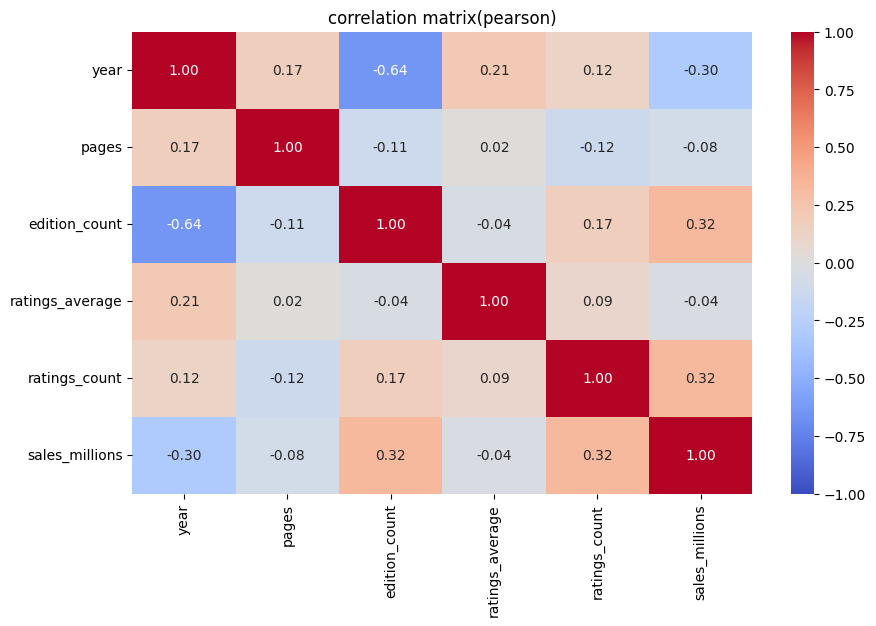

In [46]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('correlation matrix(pearson)')
plt.show()

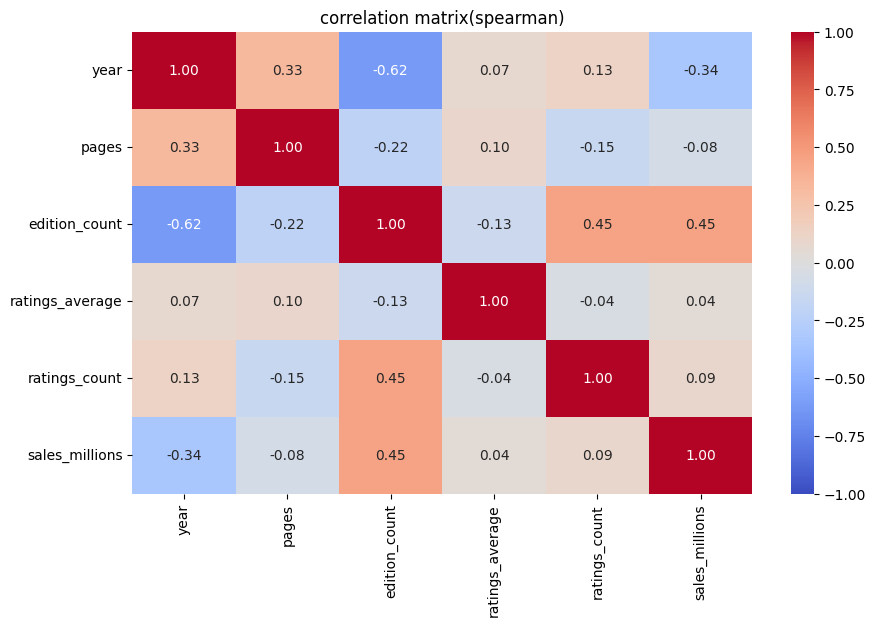

In [47]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('correlation matrix(spearman)')
plt.show()

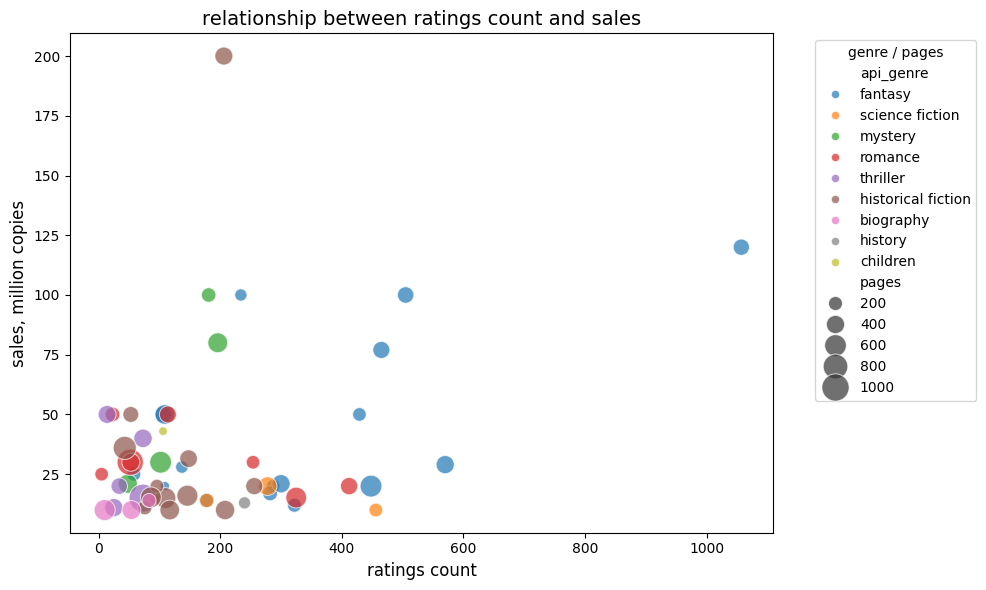

In [48]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='ratings_count',
    y='sales_millions',
    hue='api_genre',
    size='pages',
    sizes=(40, 400),
    alpha=0.7
)
plt.title('relationship between ratings count and sales', fontsize=14)
plt.xlabel('ratings count', fontsize=12)
plt.ylabel('sales, million copies', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='genre / pages')
plt.tight_layout()
plt.show()

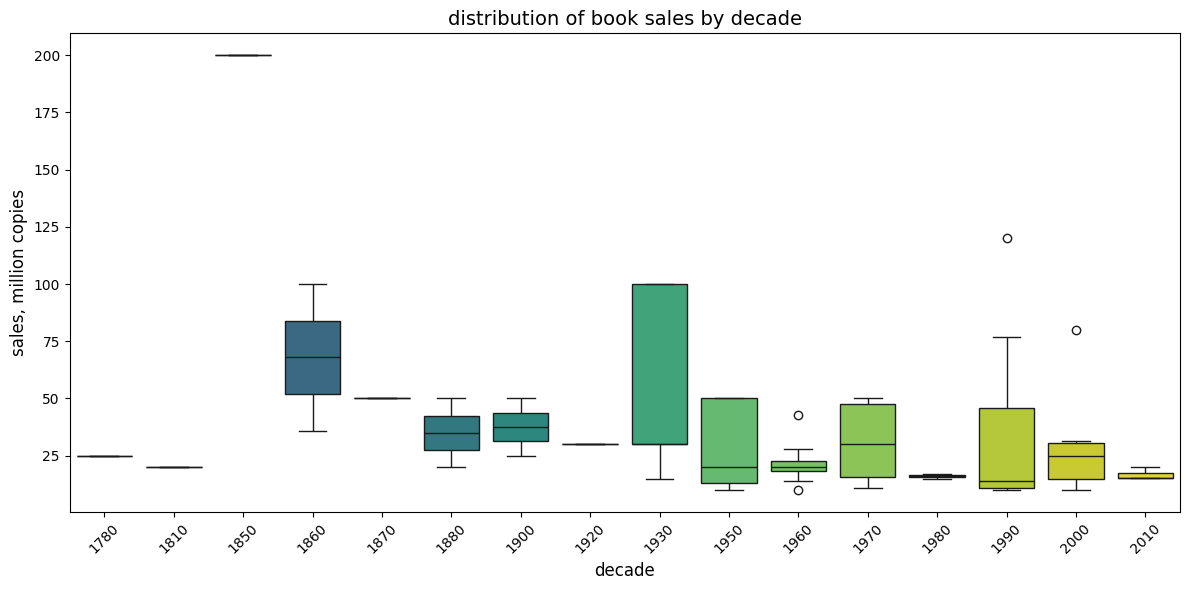

In [49]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x='decade',
    y='sales_millions',
    hue='decade',
    palette='viridis',
    legend=False
)
plt.title('distribution of book sales by decade', fontsize=14)
plt.xlabel('decade', fontsize=12)
plt.ylabel('sales, million copies', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
df['decade'].value_counts().sort_index()

decade
1780    1
1810    1
1850    1
1860    2
1870    1
1880    2
1900    2
1920    1
1930    5
1950    5
1960    8
1970    6
1980    2
1990    7
2000    8
2010    3
Name: count, dtype: int64

In [51]:
df['period'] = pd.cut(
    df['year'],
    bins=[1787, 1899, 1949, 1999, 2014],
    labels=['pre-1900', '1900-1949', '1950-1999', '2000+']
)

df['period'].value_counts()

period
1950-1999    28
2000+        11
pre-1900      8
1900-1949     8
Name: count, dtype: int64

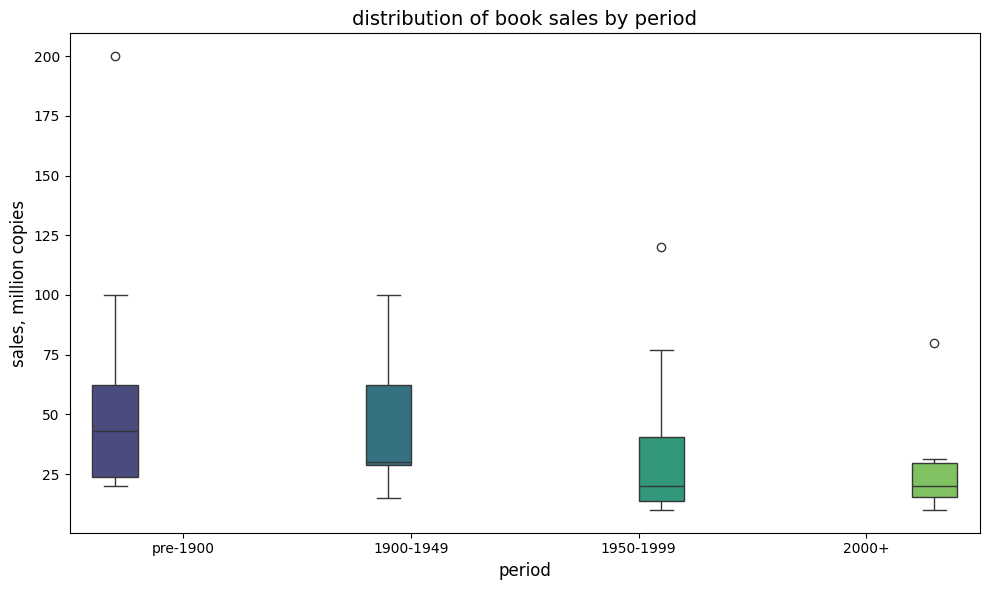

In [52]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x='period',
    y='sales_millions',
    hue='period',
    palette='viridis',
    legend=False
)
plt.title('distribution of book sales by period', fontsize=14)
plt.xlabel('period', fontsize=12)
plt.ylabel('sales, million copies', fontsize=12)
plt.tight_layout()
plt.show()